# 01 — Measurement Statistics with Qiskit

**Project:** QFlowPilot  
**Purpose:** Learn how to collect quantum measurement results with Qiskit and calculate the statistical quantities needed by a quality-aware runtime.

> **Project boundary:** QFlowPilot is an independent project. This notebook does not import, integrate, or depend on QCloudSimpy or QSimKit.

## Learning objectives

By the end of this notebook, you will be able to:
1. Build and execute a small quantum circuit using Qiskit.
2. Collect measurement counts from Qiskit Aer.
3. Convert counts into empirical probabilities.
4. Calculate expectation value, variance, standard deviation, and standard error.
5. study how shot count affects statistical uncertainty.
6. Explain why more shots do not automatically remove hardware noise or algorithmic error.

## Important experimental distinction

This notebook uses **Qiskit Aer**, a local quantum simulator. It teaches circuit execution and measurement-statistics collection. Its execution time is not cloud-QPU latency and must not be reported as real hardware performance. Later, a separate IBM Quantum adapter can collect real backend results when access is available.


## 1. Environment setup

Install the required packages in the Python environment dedicated to QFlowPilot.

Run this command in a terminal (not as a Python statement):

```bash
python -m pip install --upgrade qiskit qiskit-aer numpy matplotlib
```

If you use Jupyter, make sure the notebook kernel is connected to the same environment in which you installed these packages. Restart the kernel after installation if needed.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

SEED = 42
rng = np.random.default_rng(SEED)

simulator = AerSimulator(seed_simulator=SEED)

print("NumPy:", np.__version__)
print("Qiskit circuit and Aer simulator imported successfully.")


NumPy: 1.26.4
Qiskit circuit and Aer simulator imported successfully.


## 2. Create a simple two-qubit Bell circuit

We prepare the Bell state:

|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}


The circuit applies:
1. Hadamard gate `H` to qubit 0.
2. Controlled-NOT gate `CX` with qubit 0 as control and qubit 1 as target.
3. Measurement of both qubits.

In an ideal simulation, the outcomes `00` and `11` each have probability 0.5. Outcomes `01` and `10` have probability 0.

This is a small teaching circuit. It is not the QAOA workload; QAOA Max-Cut is introduced in Notebook 02.


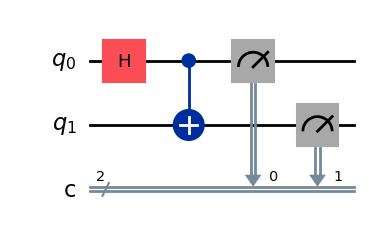

In [2]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])

qc.draw("mpl")


## 3. Execute the circuit with Qiskit Aer

A **shot** is one circuit execution followed by measurement. We request 1,000 shots in this example.

`transpile` prepares the circuit for the selected simulator backend. `get_counts` returns how many times each classical bitstring was observed.


In [7]:
N_SHOTS = 2000

compiled_circuit = transpile(qc, simulator, seed_transpiler=SEED)
job = simulator.run(compiled_circuit, shots=N_SHOTS)
result = job.result()
counts = result.get_counts(compiled_circuit)

print("Measurement counts:", counts)
print("Total shots returned:", sum(counts.values()))


Measurement counts: {'11': 1017, '00': 983}
Total shots returned: 2000


## 4. Convert counts into empirical probabilities

For a measurement outcome \(x\):

\[
\hat P(x)=\frac{n_x}{N}
\]

where:
- \(n_x\): number of times outcome \(x\) was measured.
- \(N\): total number of shots.
- \(\hat P(x)\): empirical probability estimated from the measurements.

Qiskit returns count keys as bitstrings. We include all four two-qubit outcomes in a stable order, including outcomes whose count is zero.


In [8]:
bitstrings = ["00", "01", "10", "11"]
ordered_counts = {state: int(counts.get(state, 0)) for state in bitstrings}
total_shots = sum(ordered_counts.values())

empirical_probabilities = {
    state: ordered_counts[state] / total_shots
    for state in bitstrings
}

print(f'{"Outcome":>10} {"Count":>10} {"Empirical probability":>24}')
print("-" * 48)
for state in bitstrings:
    print(f'{state:>10} {ordered_counts[state]:>10} {empirical_probabilities[state]:>24.4f}')

print("\nProbability sum:", sum(empirical_probabilities.values()))


   Outcome      Count    Empirical probability
------------------------------------------------
        00        983                   0.4915
        01          0                   0.0000
        10          0                   0.0000
        11       1017                   0.5085

Probability sum: 1.0


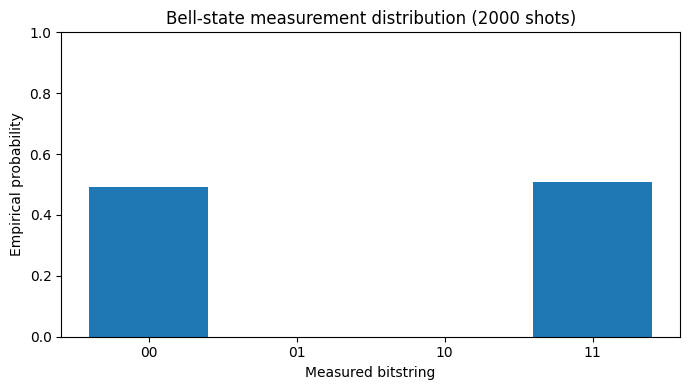

In [9]:
plt.figure(figsize=(7, 4))
plt.bar(bitstrings, [empirical_probabilities[s] for s in bitstrings])
plt.xlabel("Measured bitstring")
plt.ylabel("Empirical probability")
plt.title(f"Bell-state measurement distribution ({total_shots} shots)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 5. Define an observable

A probability distribution does not by itself tell us whether a result is useful. We calculate an observable from each measured outcome.

For this example, use the Pauli-Z observable on qubit 0. Its value is:
- `+1` when qubit 0 is measured as `0`.
- `-1` when qubit 0 is measured as `1`.

For the Bell-state outcomes, this gives:
- `00` → `+1`
- `11` → `-1`

**Qiskit bit-order note:** Qiskit displays classical bitstrings with the highest-index classical bit on the left. Here, we measured qubit 0 into classical bit 0 and qubit 1 into classical bit 1. For the two Bell outcomes (`00` and `11`), either bit has the same value, so this example is unaffected by that display convention. For more complex circuits, explicitly check the classical-bit mapping.


In [10]:
def z_on_qubit_0_from_bitstring(bitstring: str) -> float:
    # Qiskit displays c[1]...c[0]; the rightmost character is c[0].
    measured_c0 = bitstring[-1]
    return 1.0 if measured_c0 == "0" else -1.0

observable_values = {
    state: z_on_qubit_0_from_bitstring(state)
    for state in bitstrings
}

print("Observable value by outcome:", observable_values)


Observable value by outcome: {'00': 1.0, '01': -1.0, '10': 1.0, '11': -1.0}


## 6. Estimate the expectation value

The theoretical expectation of an observable is:

\[
E[f]=\sum_x P(x)f(x)
\]

We usually do not know the exact probability distribution on a real QPU. We estimate the expectation from measured shots:

\[
\hat f=\frac{1}{N}\sum_{i=1}^{N}f(x_i)
=\sum_x\hat P(x)f(x)
\]

The two calculations below should agree (up to floating-point rounding).


In [11]:
# Estimate from counts/probabilities
expectation_from_counts = sum(
    empirical_probabilities[state] * observable_values[state]
    for state in bitstrings
)

# Reconstruct one observable value for every measured shot
shot_values = np.concatenate([
    np.full(ordered_counts[state], observable_values[state], dtype=float)
    for state in bitstrings
])

expectation_from_shots = float(np.mean(shot_values))

print(f"Expectation from counts: {expectation_from_counts:.4f}")
print(f"Expectation from shots:  {expectation_from_shots:.4f}")


Expectation from counts: -0.0170
Expectation from shots:  -0.0170


## 7. Variance and standard deviation

The unbiased sample variance is:

\[
s^2=\frac{1}{N-1}\sum_{i=1}^{N}(f(x_i)-\hat f)^2
\]

The sample standard deviation is:

\[
s=\sqrt{s^2}
\]

**Interpretation:** Standard deviation measures the spread of individual measured observable values. It is not the same as the uncertainty in the estimated mean.


In [12]:
sample_variance = float(np.var(shot_values, ddof=1))
sample_std_dev = float(np.std(shot_values, ddof=1))

print(f"Sample variance:           {sample_variance:.6f}")
print(f"Sample standard deviation: {sample_std_dev:.6f}")


Sample variance:           1.000211
Sample standard deviation: 1.000106


## 8. Standard error of the estimated mean

The standard error estimates the sampling uncertainty of the sample mean:

\[
SE(\hat f)=\frac{s}{\sqrt N}
\]

where `s` is the sample standard deviation and `N` is the number of shots.

- **Standard deviation:** spread of individual measurement values.
- **Standard error:** uncertainty in the estimated mean due to finite sampling.

For sufficiently large samples, an approximate 95% normal confidence interval is:

\[
\hat f\pm1.96\,SE(\hat f)
\]

This is an approximation. For small samples, use a Student-t interval or an appropriate bootstrap method.


In [13]:
standard_error = sample_std_dev / np.sqrt(total_shots)
ci_low = expectation_from_shots - 1.96 * standard_error
ci_high = expectation_from_shots + 1.96 * standard_error

print(f"Shots: {total_shots}")
print(f"Estimated expectation: {expectation_from_shots:.4f}")
print(f"Standard error: {standard_error:.4f}")
print(f"Approximate 95% CI: [{ci_low:.4f}, {ci_high:.4f}]")


Shots: 2000
Estimated expectation: -0.0170
Standard error: 0.0224
Approximate 95% CI: [-0.0608, 0.0268]


## 9. Study different shot budgets using Qiskit

Now execute the same Qiskit circuit with different shot budgets. Each run is a new simulator job. We collect counts and calculate the expectation, sample standard deviation, standard error, and absolute error from the ideal expectation.

For the ideal Bell state, the theoretical expectation of Z on either qubit is zero. This known value is available because we constructed an ideal circuit. On a real device, the exact hardware distribution is generally not known to the runtime.


In [14]:
shot_budgets = [50, 100, 250, 500, 1000, 2500, 5000, 10000]
ideal_expectation = 0.0
rows = []

for n_shots in shot_budgets:
    run_job = simulator.run(compiled_circuit, shots=n_shots)
    run_counts = run_job.result().get_counts(compiled_circuit)

    values = []
    for state, count in run_counts.items():
        values.extend([z_on_qubit_0_from_bitstring(state)] * int(count))

    values = np.asarray(values, dtype=float)
    mean_value = float(np.mean(values))
    std_value = float(np.std(values, ddof=1)) if n_shots > 1 else float("nan")
    se_value = std_value / np.sqrt(n_shots)
    abs_error = abs(mean_value - ideal_expectation)

    rows.append({
        "shots": n_shots,
        "expectation": mean_value,
        "std_dev": std_value,
        "standard_error": se_value,
        "absolute_error": abs_error,
    })

print(f'{"Shots":>8} {"Expectation":>14} {"Std dev":>12} {"Std error":>12} {"Abs error":>12}')
print("-" * 64)
for row in rows:
    print(
        f'{row["shots"]:8d} {row["expectation"]:14.4f} '
        f'{row["std_dev"]:12.4f} {row["standard_error"]:12.4f} '
        f'{row["absolute_error"]:12.4f}'
    )


   Shots    Expectation      Std dev    Std error    Abs error
----------------------------------------------------------------
      50        -0.1600       0.9971       0.1410       0.1600
     100        -0.0400       1.0042       0.1004       0.0400
     250         0.0000       1.0020       0.0634       0.0000
     500         0.0440       1.0000       0.0447       0.0440
    1000         0.0200       1.0003       0.0316       0.0200
    2500        -0.0136       1.0001       0.0200       0.0136
    5000        -0.0284       0.9997       0.0141       0.0284
   10000        -0.0136       1.0000       0.0100       0.0136


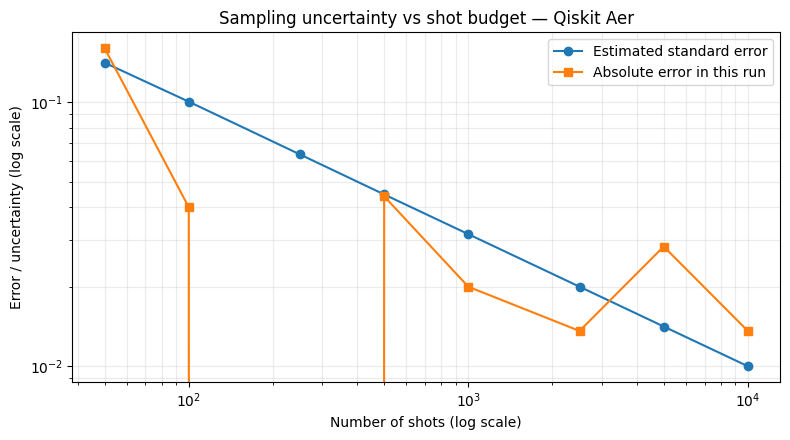

In [15]:
budgets = np.array([row["shots"] for row in rows])
standard_errors = np.array([row["standard_error"] for row in rows])
absolute_errors = np.array([row["absolute_error"] for row in rows])

plt.figure(figsize=(8, 4.5))
plt.plot(budgets, standard_errors, marker="o", label="Estimated standard error")
plt.plot(budgets, absolute_errors, marker="s", label="Absolute error in this run")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of shots (log scale)")
plt.ylabel("Error / uncertainty (log scale)")
plt.title("Sampling uncertainty vs shot budget — Qiskit Aer")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


## 10. What more shots can and cannot do

**More shots can:**
- Improve the precision of estimates of measurement probabilities and expectation values.
- Reduce sampling uncertainty when the underlying distribution is stable and shots are sufficiently independent.

**More shots cannot automatically:**
- Remove systematic hardware noise or calibration bias.
- Correct a poor circuit or unsuitable algorithm parameters.
- Guarantee a high-quality application-level answer.
- Guarantee that QAOA finds the optimal Max-Cut bitstring.

This distinction is important for QFlowPilot: a smaller standard error is not proof that the application result is good. Notebook 02 will introduce QAOA Max-Cut quality measures.


## 11. Research notes and exercises

Answer these questions after running the notebook:

1. Why do the ideal Bell-state measurements produce only `00` and `11`?
2. Why can the measured counts differ from an exact 50/50 split?
3. What is the difference between standard deviation and standard error?
4. Does the absolute error decrease monotonically for every shot budget? Explain.
5. What kinds of error may remain even with a very large number of shots?
6. Why must local Aer execution time not be described as real cloud-QPU latency?

### Main equations

Empirical probability:

\[
\hat P(x)=\frac{n_x}{N}
\]

Estimated expectation:

\[
\hat f=\frac{1}{N}\sum_{i=1}^{N}f(x_i)
\]

Sample variance:

\[
s^2=\frac{1}{N-1}\sum_{i=1}^{N}(f(x_i)-\hat f)^2
\]

Standard error:

\[
SE(\hat f)=\frac{s}{\sqrt N}
\]

### Completion checklist

- [ ] Install Qiskit and Qiskit Aer in the QFlowPilot environment.
- [ ] Run every notebook cell successfully.
- [ ] Inspect the circuit diagram and measurement counts.
- [ ] Confirm that empirical probabilities sum to approximately 1.
- [ ] Explain expectation, variance, standard deviation, and standard error.
- [ ] Save the plots and write short answers to the six research questions.
- [ ] Keep simulator results clearly separate from real QPU results.


Empirical probability

Simple meaning: It calculates how often a particular measurement result occurs.

Empirical probability:

\[
\hat P(x)=\frac{n_x}{N}
\]

- \(x\): A measurement result, such as 00 or 11.
- \(n_x\): Number of times that result appears.
- \(N\): Total number of circuit executions (shots).



Example:

Suppose you execute a Bell-state circuit 1,000 times.
Measurement	Counts
00	510
11	490
01	0
10	0

Probability of getting 00:
\[
\hat P(00)=\frac{510}{1000}=0.51
\]

Probability of getting 11:
\[
\hat P(11)=\frac{490}{1000}=0.49
\]

Why do you use this equation?

To understand the probability of each measurement outcome. It helps you check whether the quantum circuit produces the expected results.

2. Estimated expectation

Estimated expectation:

\[
\hat f=\frac{1}{N}\sum_{i=1}^{N}f(x_i)
\]

Example:

Suppose your measurement results are:

1, 0, 1, 1, 0

The average is:
\[
\hat f=\frac{1+0+1+1+0}{5}=0.6
\]

This means the average measured value is 0.6.

Why do you use this equation?

Quantum algorithms often estimate values using repeated measurements. For example, in QAOA and VQE, you estimate the expectation value of an observable (such as energy or a cost function).

This equation tells you the average estimated result from your measurements.

3. Sample variance

Sample variance:

\[
s^2=\frac{1}{N-1}\sum_{i=1}^{N}(f(x_i)-\hat f)^2
\]

Simple meaning: It measures how much the individual measurement results differ from their average.

For example:
- Average result = 0.6.
- Some measurements are 0.
- Some measurements are 1.

Why do you use this equation?

Quantum measurements are probabilistic. You need to understand how much variation exists in your measurement results.

Higher variance means more variation in individual measurements.

Lower variance means measurements are more concentrated around the average.

4. Standard error

Standard error:

\[
SE(\hat f)=\frac{s}{\sqrt N}
\]

Simple meaning: It estimates how much uncertainty exists in your calculated average.
- \(s\): Standard deviation of individual measurements.
- \(N\): Number of shots.
Example:

Suppose:
- Standard deviation = 0.5.
- Number of shots = 100.
Then:
\[
SE=\frac{0.5}{\sqrt{100}}=0.05
\]

Now increase the shots to 1,000:
\[
SE=\frac{0.5}{\sqrt{1000}}\approx0.0158
\]

The uncertainty in the estimated average becomes smaller.

Why do you use this equation?

To understand how the number of shots affects the reliability of quantum measurement results.

This is particularly important for your quality-aware runtime research because you want to determine whether additional shots are worth their execution cost.

6. Why are these six research questions included?
These are not random questions. They check whether you understand the experimental results rather than simply running Python code.
Question	Why it is important
1. Why do Bell measurements produce only 00 and 11?	Understand quantum entanglement.
2. Why can counts differ from 50/50?	Understand measurement randomness.
3. Standard deviation vs standard error?	Understand individual variation vs uncertainty in the average.
4. Does absolute error decrease monotonically?	Understand that more shots do not guarantee improvement in every individual experiment.
5. What errors remain with many shots?	Understand hardware noise, bias, and systematic errors.
6. Why is Aer execution time not real cloud-QPU latency?	Understand the difference between local simulation and real quantum cloud execution.

7. Connection with your QFlowPilot research
These equations establish your mathematical foundation for understanding quantum measurement quality.

Consider this example:

Your runtime executes a QAOA circuit with 100 shots. The estimated result has relatively high uncertainty.

The runtime can decide to execute another 900 shots.

After 1,000 total shots, it recalculates the expectation and standard error.

The runtime can then evaluate whether the additional shots improved confidence enough to justify their execution cost.

This is the basic idea behind quality-aware execution.
The research question you are ultimately trying to answer:

How many shots should a quantum runtime allocate to obtain sufficiently reliable results without wasting execution time and computational resources?